# Assignment 10: Generative Adversarial Network (GAN) on MNIST — Fast Discriminator Regime (D_lr > G_lr)
**Author:** Kristian Hudák  
**Course:** AI Olympiad (OAI) Preparation Course

Empirical investigation of training dynamics when the Discriminator learns faster than the Generator, analyzing risks of vanishing gradients for the generator.

**Pipeline Overview:**
- **Generator Architecture:** Multi-layer feedforward network with LeakyReLU activations and Tanh output generating 28x28 normalized images from a 100D Gaussian latent noise vector.
- **Discriminator Architecture:** Binary classifier evaluating real MNIST digits vs generated fakes with LeakyReLU non-linearities and Sigmoid probability output.
- **Minimax Optimization:** Binary Cross Entropy Loss (`BCELoss`) with Adam optimizer.
- **Generative Evaluation:** Tracking loss trajectories, generating synthetic digit grids, and performing smooth linear interpolation between latent code vectors ($z_1 \to z_2$).


## 1. Environment Setup & MNIST Dataset Ingestion


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import clear_output

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Používam zariadenie: {device}")


Používam zariadenie: cuda


In [2]:
# Hyperparameters
BATCH_SIZE = 128
EPOCHS = 50
LATENT_DIM = 100
LR_G = 0.0001 # rychlost ucenia generatora
LR_D = 0.0004 # rychlost ucenia diskriminatora
BETA1 = 0.5

# Load MNIST dataset
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])  # Normalizácia do [-1, 1]
])

train_dataset = datasets.MNIST('./data', train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

print(f"Trénovacích vzoriek: {len(train_dataset)}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Počet batches: {len(train_loader)}")


100%|██████████| 9.91M/9.91M [00:02<00:00, 4.06MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 130kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.21MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.08MB/s]

Trénovacích vzoriek: 60000
Batch size: 128
Počet batches: 468


## 2. Generator Architecture Definition


In [3]:
class Generator(nn.Module):
    def __init__(self, latent_dim=100):
        super(Generator, self).__init__()

        self.model = nn.Sequential(
            # Vstup: latent_dim (napr. 100)
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2),    # nenulovy gradient (inak "zomierajuce" neurony - neucia sa)
            nn.BatchNorm1d(256),  # brani explozii gradientov -> stabilnejsi trening

            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(512),

            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(1024),

            nn.Linear(1024, 784),  # 28*28 = 784
            nn.Tanh()  # Výstup v [-1, 1] -> stabilnejsi trening
        )

    def forward(self, z):
        img = self.model(z)
        img = img.view(img.size(0), 1, 28, 28)
        return img

generator = Generator(LATENT_DIM).to(device)
print("Generator:")
print(generator)
print(f"\nPočet parametrov: {sum(p.numel() for p in generator.parameters())}")


Generator:
Generator(
  (model): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Linear(in_features=256, out_features=512, bias=True)
    (4): LeakyReLU(negative_slope=0.2)
    (5): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): Linear(in_features=512, out_features=1024, bias=True)
    (7): LeakyReLU(negative_slope=0.2)
    (8): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): Linear(in_features=1024, out_features=784, bias=True)
    (10): Tanh()
  )
)

Počet parametrov: 1489936


## 3. Discriminator Architecture Definition


In [4]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()

        self.model = nn.Sequential(
            # Vstup: 784 (28*28)
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),

            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),

            nn.Linear(256, 1),
            nn.Sigmoid()  # Výstup: pravdepodobnosť [0, 1]
        )

    def forward(self, img):
        img_flat = img.view(img.size(0), -1)
        validity = self.model(img_flat)
        return validity

discriminator = Discriminator().to(device)
print("Discriminator:")
print(discriminator)
print(f"\nPočet parametrov: {sum(p.numel() for p in discriminator.parameters())}")


Discriminator:
Discriminator(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): LeakyReLU(negative_slope=0.2)
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=256, out_features=1, bias=True)
    (7): Sigmoid()
  )
)

Počet parametrov: 533505


## 4. Objective Loss Function & Optimizers


In [5]:
# Binary Cross Entropy loss
adversarial_loss = nn.BCELoss() # Probability that image is real

# Optimizéry - samostatne pre G a D
optimizer_G = optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

print("Loss funkcia a optimizéry pripravené!")


Loss funkcia a optimizéry pripravené!


## 5. Adversarial Training Loop (Minimax Game)


ZAČÍNAM TRÉNOVANIE GAN
Epocha [1/50] | D Loss: 0.2010 | G Loss: 2.9596 | D Acc: 92.4%
Epocha [2/50] | D Loss: 0.4439 | G Loss: 1.1362 | D Acc: 84.2%
Epocha [3/50] | D Loss: 0.4741 | G Loss: 1.1634 | D Acc: 82.1%
Epocha [4/50] | D Loss: 0.4925 | G Loss: 1.2837 | D Acc: 77.4%
Epocha [5/50] | D Loss: 0.4997 | G Loss: 1.2969 | D Acc: 75.9%


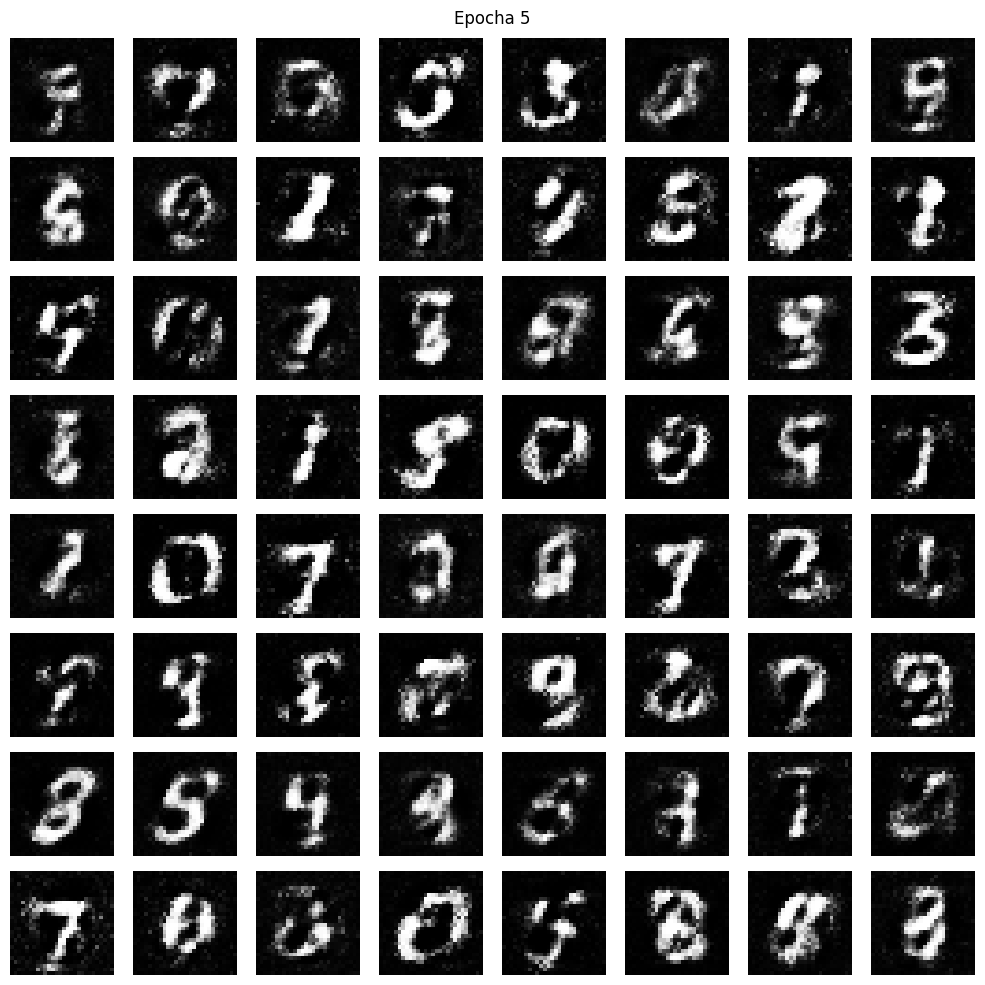

Epocha [6/50] | D Loss: 0.5099 | G Loss: 1.2624 | D Acc: 75.2%
Epocha [7/50] | D Loss: 0.5246 | G Loss: 1.2099 | D Acc: 74.0%
Epocha [8/50] | D Loss: 0.5419 | G Loss: 1.1559 | D Acc: 72.6%
Epocha [9/50] | D Loss: 0.5543 | G Loss: 1.1198 | D Acc: 71.5%
Epocha [10/50] | D Loss: 0.5671 | G Loss: 1.0814 | D Acc: 70.5%


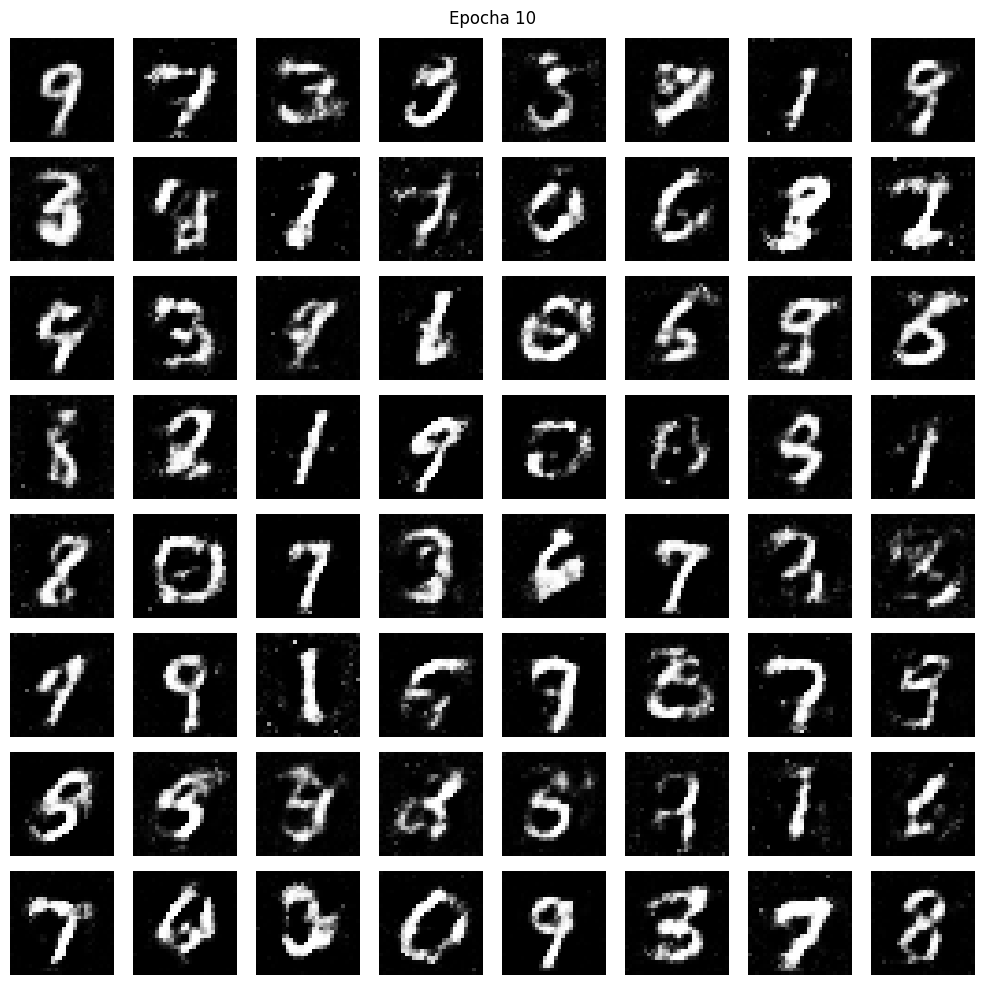

Epocha [11/50] | D Loss: 0.5822 | G Loss: 1.0439 | D Acc: 69.0%
Epocha [12/50] | D Loss: 0.5945 | G Loss: 1.0154 | D Acc: 68.0%
Epocha [13/50] | D Loss: 0.6062 | G Loss: 0.9771 | D Acc: 66.8%
Epocha [14/50] | D Loss: 0.6126 | G Loss: 0.9640 | D Acc: 66.4%
Epocha [15/50] | D Loss: 0.6186 | G Loss: 0.9406 | D Acc: 65.6%


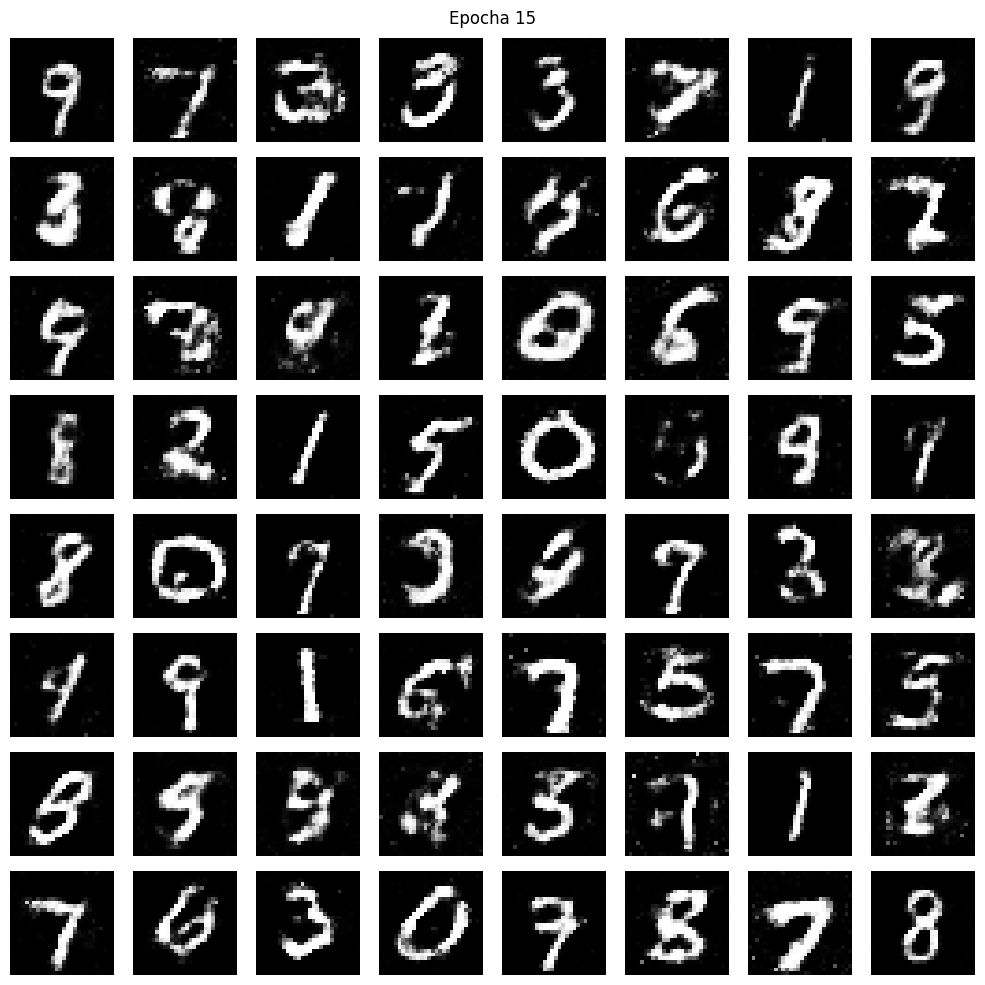

Epocha [16/50] | D Loss: 0.6220 | G Loss: 0.9360 | D Acc: 65.2%
Epocha [17/50] | D Loss: 0.6275 | G Loss: 0.9167 | D Acc: 64.5%
Epocha [18/50] | D Loss: 0.6314 | G Loss: 0.8974 | D Acc: 64.2%
Epocha [19/50] | D Loss: 0.6346 | G Loss: 0.8933 | D Acc: 63.7%
Epocha [20/50] | D Loss: 0.6375 | G Loss: 0.8809 | D Acc: 63.4%


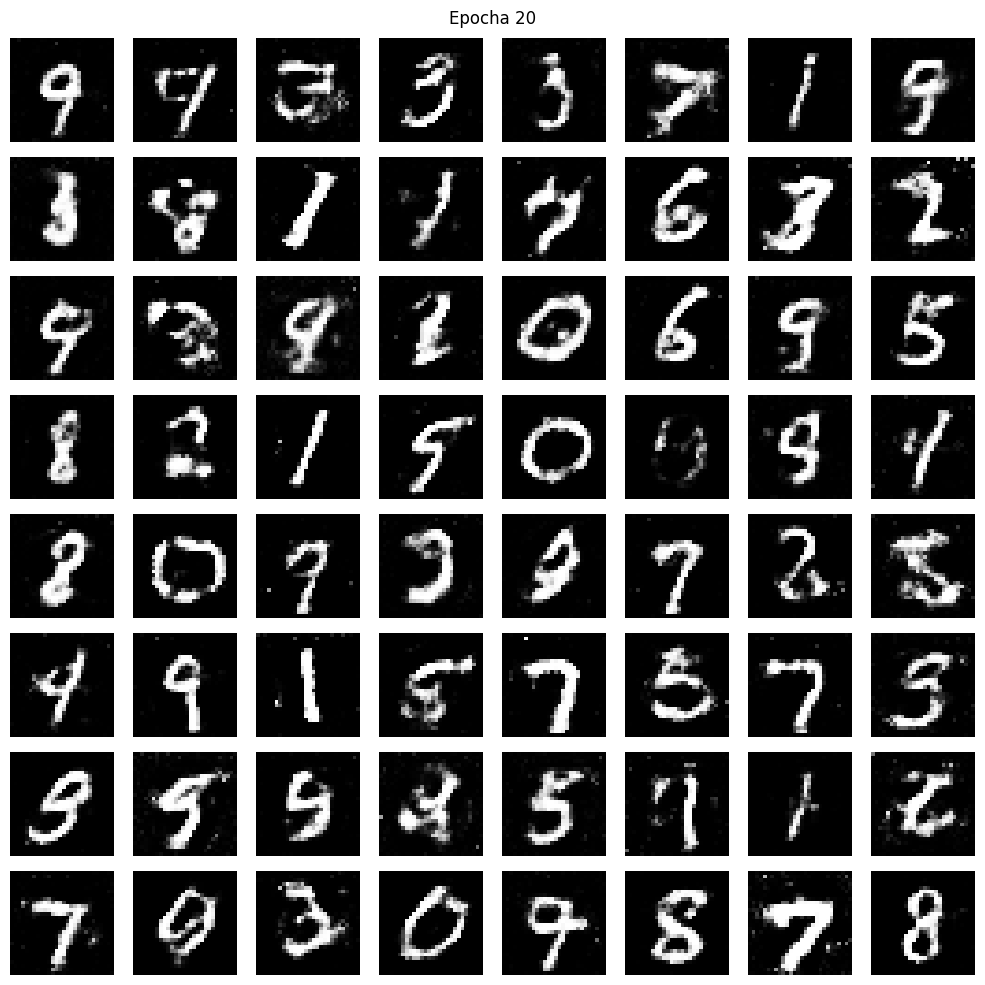

Epocha [21/50] | D Loss: 0.6421 | G Loss: 0.8726 | D Acc: 62.9%
Epocha [22/50] | D Loss: 0.6441 | G Loss: 0.8621 | D Acc: 62.6%
Epocha [23/50] | D Loss: 0.6456 | G Loss: 0.8579 | D Acc: 62.4%
Epocha [24/50] | D Loss: 0.6469 | G Loss: 0.8491 | D Acc: 62.1%
Epocha [25/50] | D Loss: 0.6502 | G Loss: 0.8407 | D Acc: 61.8%


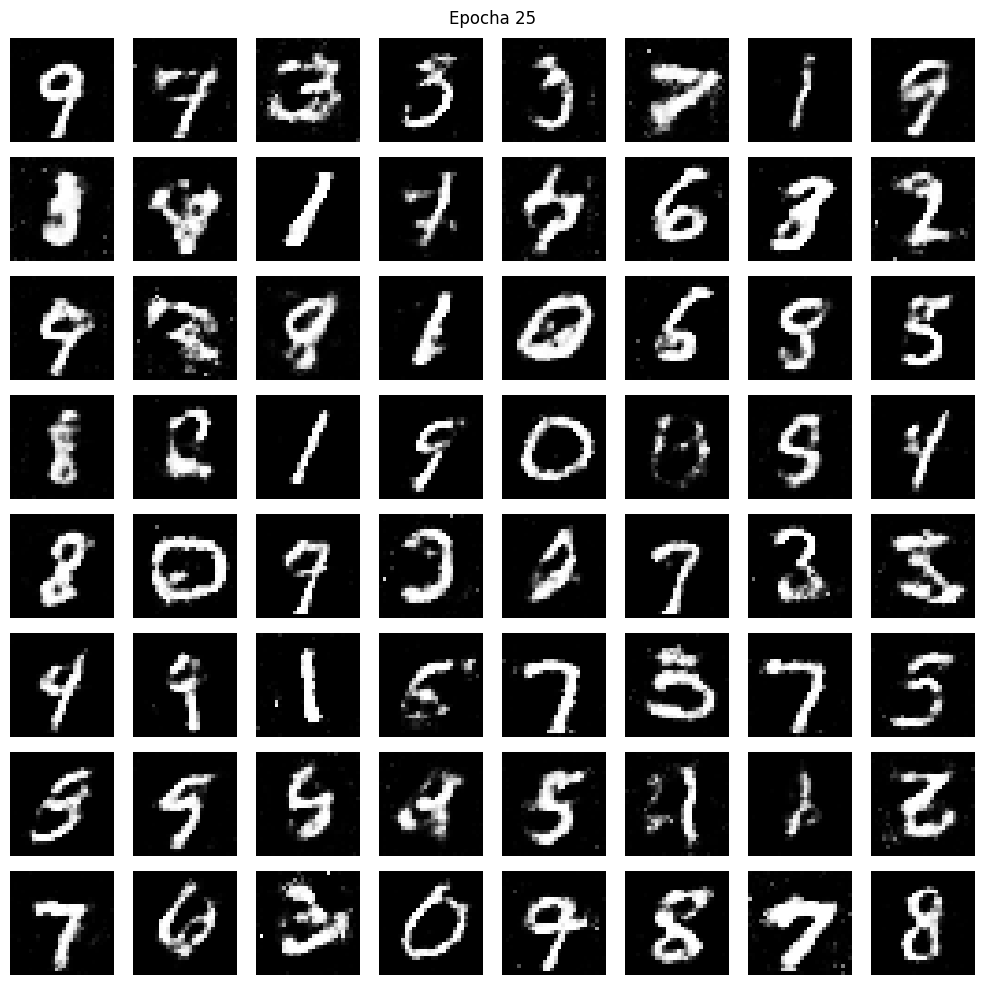

Epocha [26/50] | D Loss: 0.6514 | G Loss: 0.8359 | D Acc: 61.5%
Epocha [27/50] | D Loss: 0.6528 | G Loss: 0.8313 | D Acc: 61.6%
Epocha [28/50] | D Loss: 0.6536 | G Loss: 0.8276 | D Acc: 61.2%
Epocha [29/50] | D Loss: 0.6552 | G Loss: 0.8230 | D Acc: 60.9%
Epocha [30/50] | D Loss: 0.6565 | G Loss: 0.8179 | D Acc: 60.8%


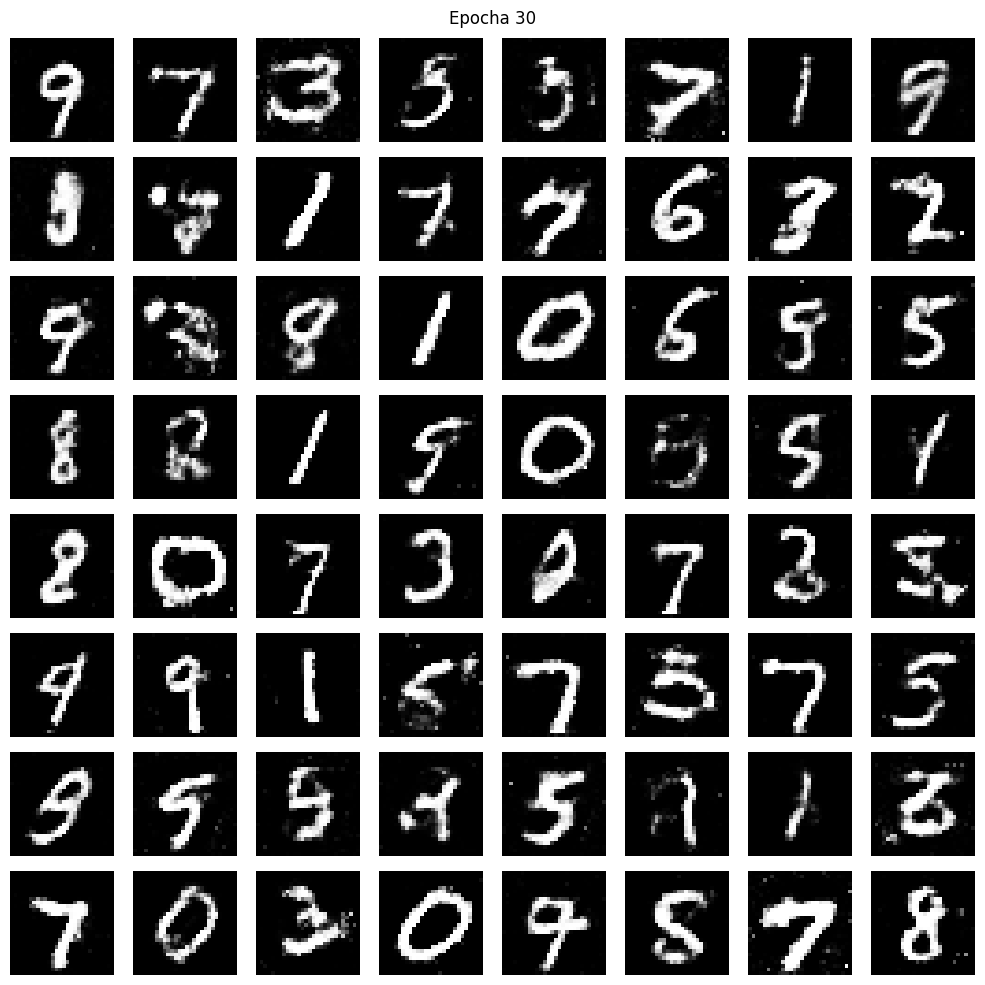

Epocha [31/50] | D Loss: 0.6568 | G Loss: 0.8135 | D Acc: 60.6%
Epocha [32/50] | D Loss: 0.6576 | G Loss: 0.8119 | D Acc: 60.7%
Epocha [33/50] | D Loss: 0.6584 | G Loss: 0.8078 | D Acc: 60.3%
Epocha [34/50] | D Loss: 0.6603 | G Loss: 0.8039 | D Acc: 60.2%
Epocha [35/50] | D Loss: 0.6612 | G Loss: 0.7993 | D Acc: 60.0%


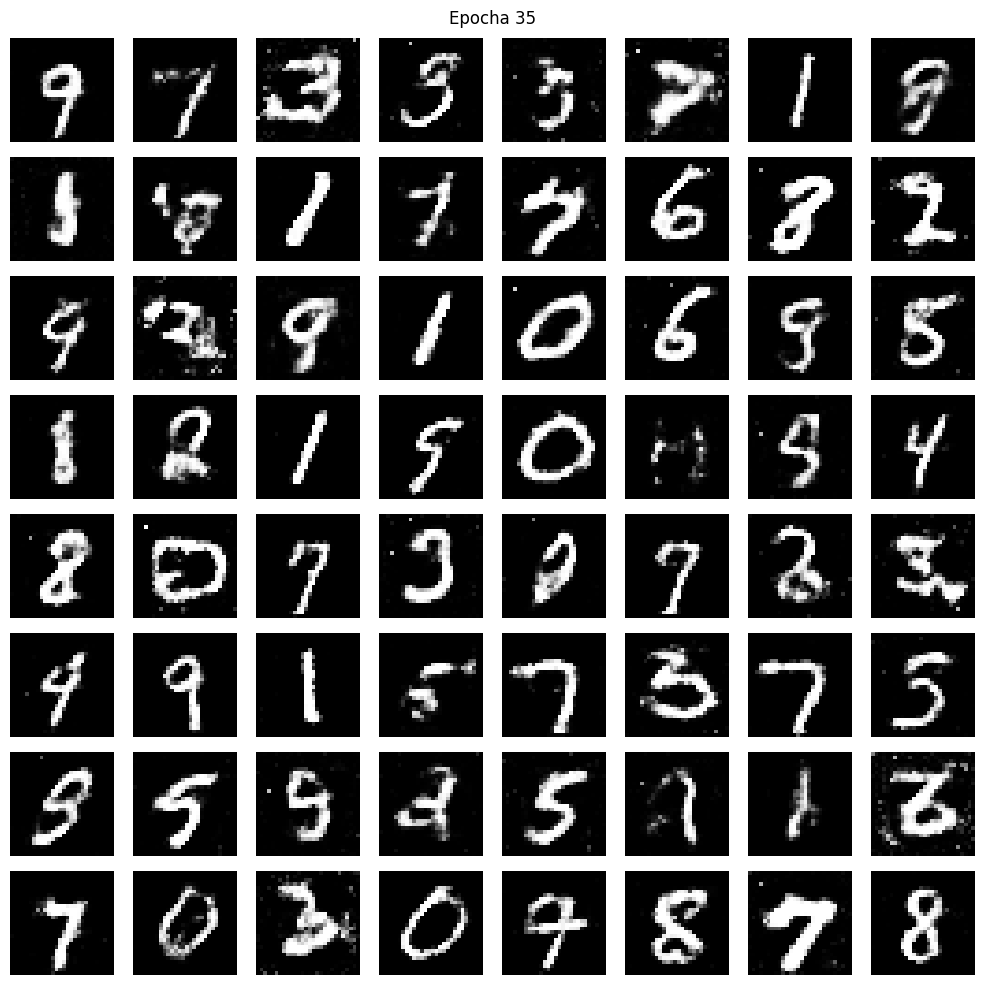

Epocha [36/50] | D Loss: 0.6622 | G Loss: 0.7965 | D Acc: 59.9%
Epocha [37/50] | D Loss: 0.6625 | G Loss: 0.7952 | D Acc: 59.6%
Epocha [38/50] | D Loss: 0.6630 | G Loss: 0.7932 | D Acc: 59.8%
Epocha [39/50] | D Loss: 0.6633 | G Loss: 0.7958 | D Acc: 59.8%
Epocha [40/50] | D Loss: 0.6652 | G Loss: 0.7885 | D Acc: 59.5%


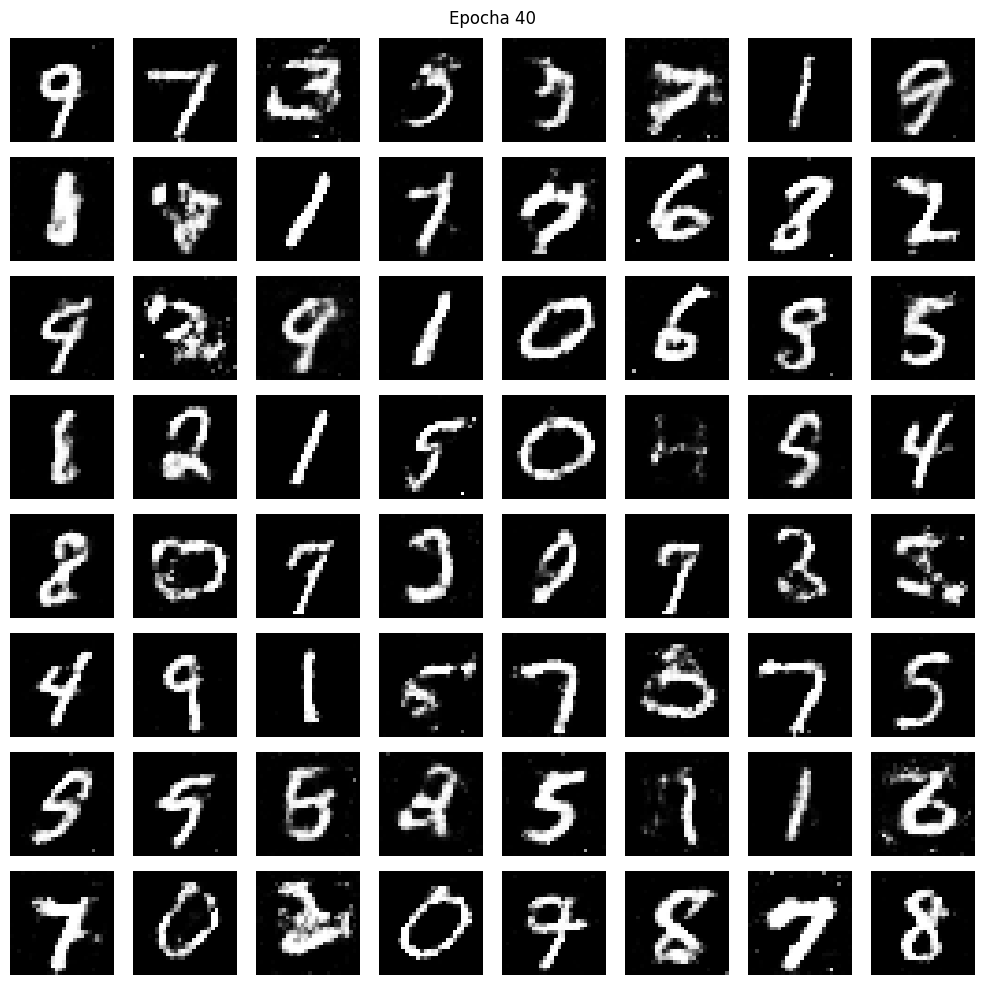

Epocha [41/50] | D Loss: 0.6653 | G Loss: 0.7881 | D Acc: 59.2%
Epocha [42/50] | D Loss: 0.6667 | G Loss: 0.7824 | D Acc: 59.0%
Epocha [43/50] | D Loss: 0.6662 | G Loss: 0.7831 | D Acc: 59.2%
Epocha [44/50] | D Loss: 0.6667 | G Loss: 0.7814 | D Acc: 59.0%
Epocha [45/50] | D Loss: 0.6666 | G Loss: 0.7807 | D Acc: 59.1%


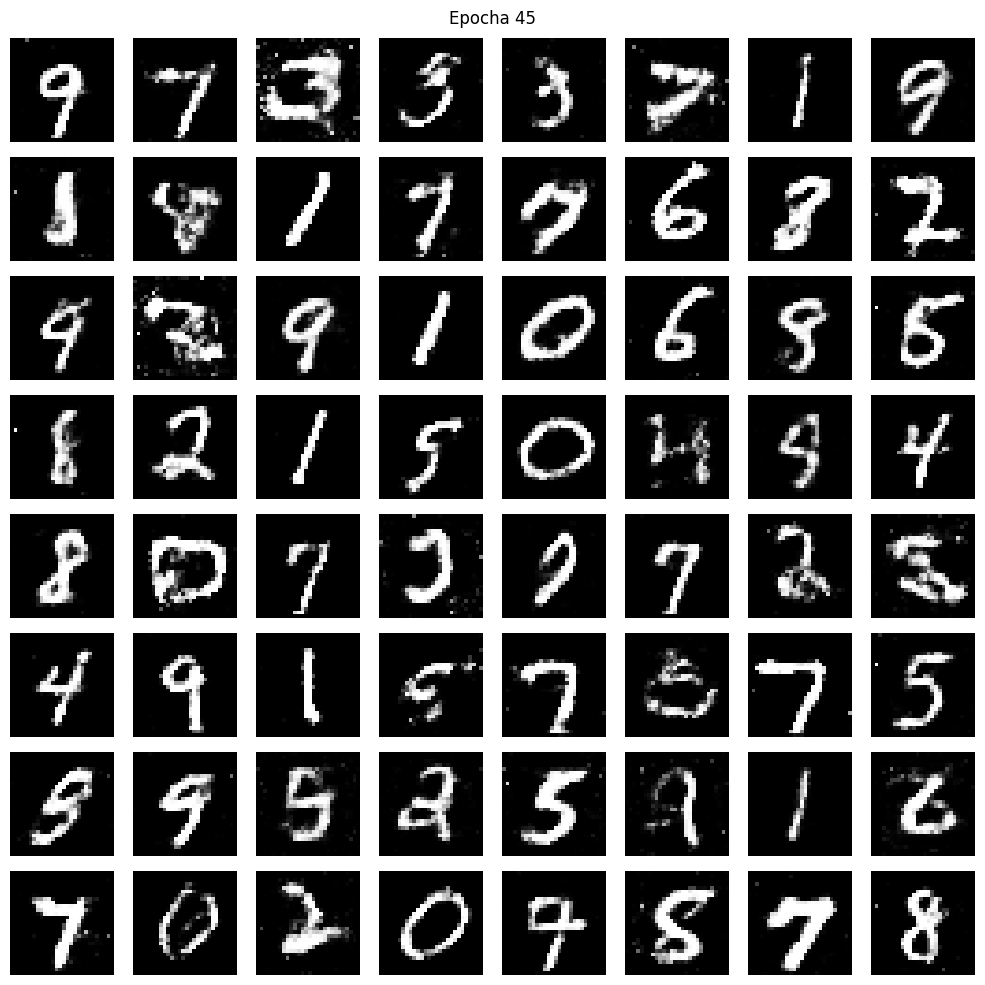

Epocha [46/50] | D Loss: 0.6679 | G Loss: 0.7801 | D Acc: 58.8%
Epocha [47/50] | D Loss: 0.6679 | G Loss: 0.7795 | D Acc: 58.8%
Epocha [48/50] | D Loss: 0.6686 | G Loss: 0.7762 | D Acc: 58.8%
Epocha [49/50] | D Loss: 0.6692 | G Loss: 0.7761 | D Acc: 58.7%
Epocha [50/50] | D Loss: 0.6691 | G Loss: 0.7736 | D Acc: 58.7%


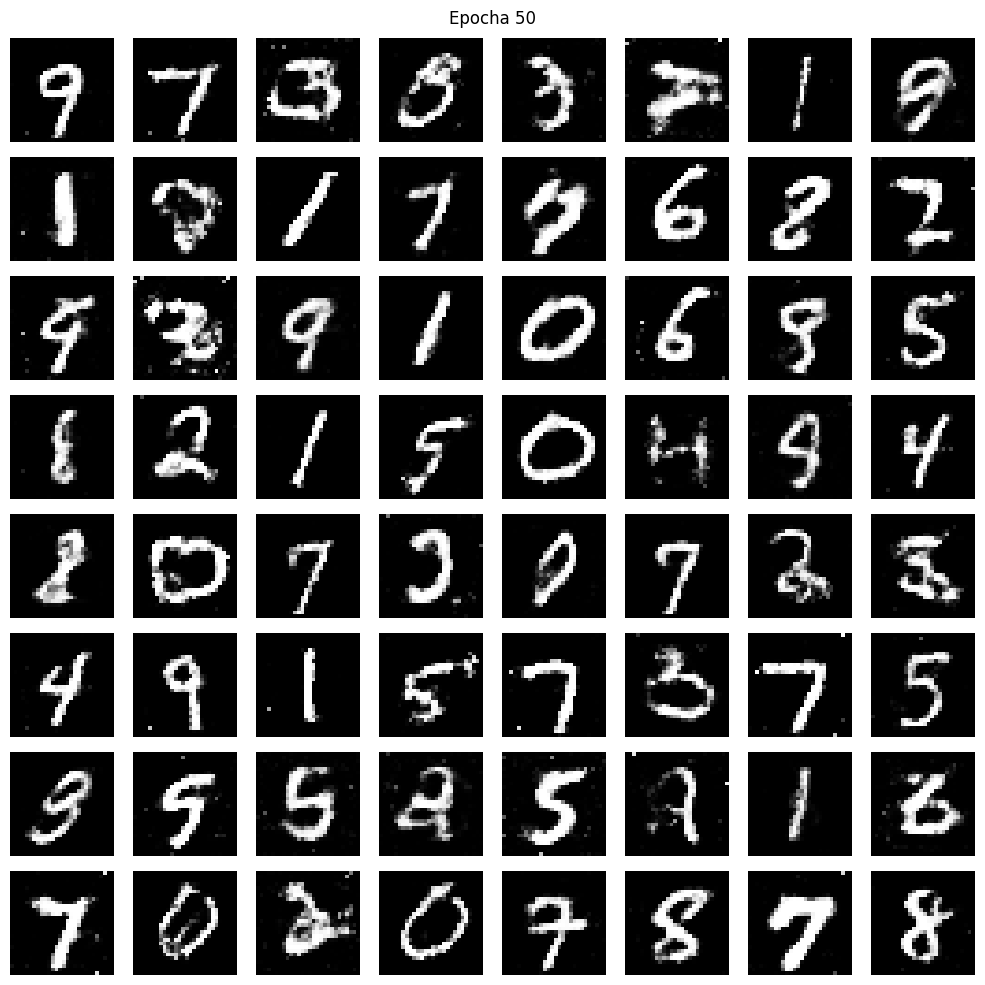

In [6]:
def train_gan():
    g_losses = []
    d_losses = []
    d_accuracies = []

    # Fixný šum (latentne vektory) pre vizualizáciu progresu
    fixed_noise = torch.randn(64, LATENT_DIM, device=device)

    print("="*60)
    print("ZAČÍNAM TRÉNOVANIE GAN")
    print("="*60)

    for epoch in range(EPOCHS):
        epoch_g_loss = 0
        epoch_d_loss = 0
        epoch_d_acc = 0

        for i, (real_imgs, _) in enumerate(train_loader):
            batch_size = real_imgs.size(0)
            real_imgs = real_imgs.to(device)

            # Labels
            real_labels = torch.ones(batch_size, 1, device=device)  # jednotky
            fake_labels = torch.zeros(batch_size, 1, device=device) # nuly

            # =====================
            # Trénuj DISKRIMINÁTOR
            # =====================
            optimizer_D.zero_grad()

            # Real images
            real_validity = discriminator(real_imgs) # diskriminator hodnoti realne obrazky
            d_real_loss = adversarial_loss(real_validity, real_labels)

            # Fake images
            z = torch.randn(batch_size, LATENT_DIM, device=device) # latentne vektory
            fake_imgs = generator(z)  # generovanie obrazkov z latentnych vektorov
            fake_validity = discriminator(fake_imgs.detach()) # diskriminator hodnoti falosne obrazky
            d_fake_loss = adversarial_loss(fake_validity, fake_labels)

            # Total discriminator loss
            d_loss = (d_real_loss + d_fake_loss) / 2
            d_loss.backward()
            optimizer_D.step()

            # Presnosť diskriminátora
            real_acc = (real_validity > 0.5).float().mean()
            fake_acc = (fake_validity < 0.5).float().mean()
            d_acc = (real_acc + fake_acc) / 2

            # ===================
            # Trénuj GENERÁTOR
            # ===================
            optimizer_G.zero_grad()

            z = torch.randn(batch_size, LATENT_DIM, device=device) # latentne vektory
            gen_imgs = generator(z) # generovanie obrazkov z latentnych vektorov
            validity = discriminator(gen_imgs) # diskriminator hodnoti falosne obrazky

            # Generátor chce, aby D myslel, že fake je real!
            g_loss = adversarial_loss(validity, real_labels) # pouzijeme real labels namiesto fake labels
            g_loss.backward()
            optimizer_G.step()

            # Štatistiky
            epoch_g_loss += g_loss.item()
            epoch_d_loss += d_loss.item()
            epoch_d_acc += d_acc.item()

        # Priemerné hodnoty pre epochu
        avg_g_loss = epoch_g_loss / len(train_loader)
        avg_d_loss = epoch_d_loss / len(train_loader)
        avg_d_acc = epoch_d_acc / len(train_loader)

        g_losses.append(avg_g_loss)
        d_losses.append(avg_d_loss)
        d_accuracies.append(avg_d_acc)

        # Výpis progress
        print(f"Epocha [{epoch+1}/{EPOCHS}] | "
              f"D Loss: {avg_d_loss:.4f} | "
              f"G Loss: {avg_g_loss:.4f} | "
              f"D Acc: {avg_d_acc*100:.1f}%")

        # Vizualizácia progress každých 5 epoch
        if (epoch + 1) % 5 == 0:
            generator.eval()
            with torch.no_grad():
                fake = generator(fixed_noise)
            generator.train()

            plt.figure(figsize=(10, 10))
            for i in range(64):
                plt.subplot(8, 8, i+1)
                plt.imshow(fake[i].cpu().squeeze(), cmap='gray')
                plt.axis('off')
            plt.suptitle(f'Epocha {epoch+1}')
            plt.tight_layout()
            plt.show()

    return g_losses, d_losses, d_accuracies

# Spustenie tréningu
g_losses, d_losses, d_accuracies = train_gan()


## 6. Training Loss & Discriminator Accuracy Visualization


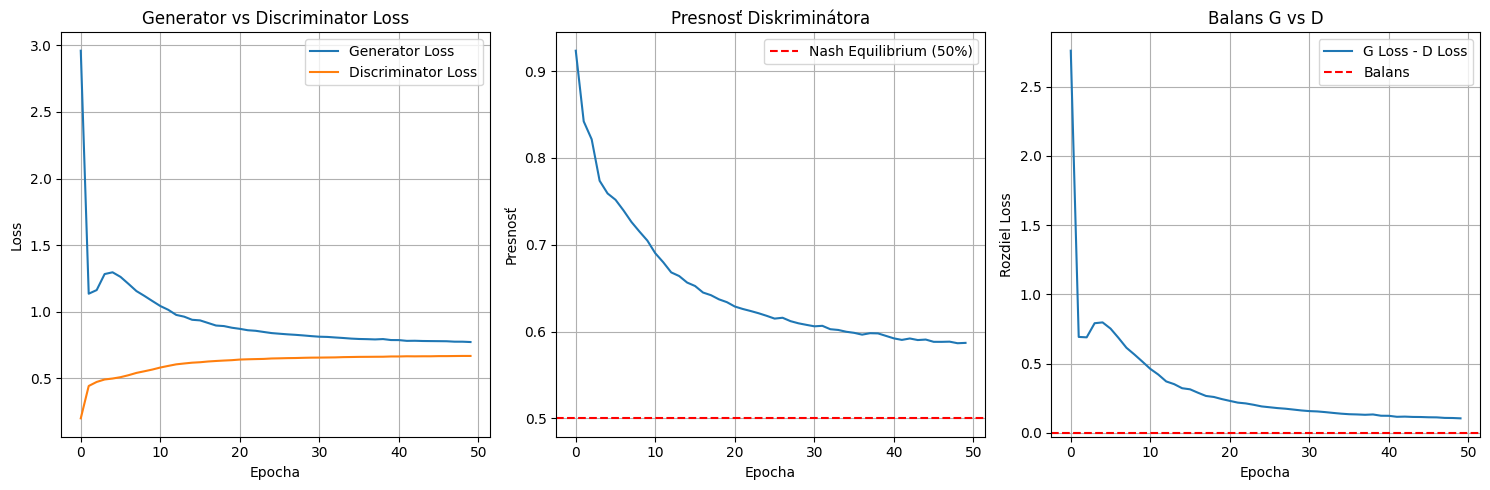

In [7]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(g_losses, label='Generator Loss')
plt.plot(d_losses, label='Discriminator Loss')
plt.xlabel('Epocha')
plt.ylabel('Loss')
plt.title('Generator vs Discriminator Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(d_accuracies)
plt.axhline(y=0.5, color='r', linestyle='--', label='Nash Equilibrium (50%)')
plt.xlabel('Epocha')
plt.ylabel('Presnosť')
plt.title('Presnosť Diskriminátora')
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(np.array(g_losses) - np.array(d_losses), label='G Loss - D Loss')
plt.axhline(y=0, color='r', linestyle='--', label='Balans')
plt.xlabel('Epocha')
plt.ylabel('Rozdiel Loss')
plt.title('Balans G vs D')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


## 7. Generating Novel Synthetic Digits


GENEROVANIE NOVÝCH OBRÁZKOV


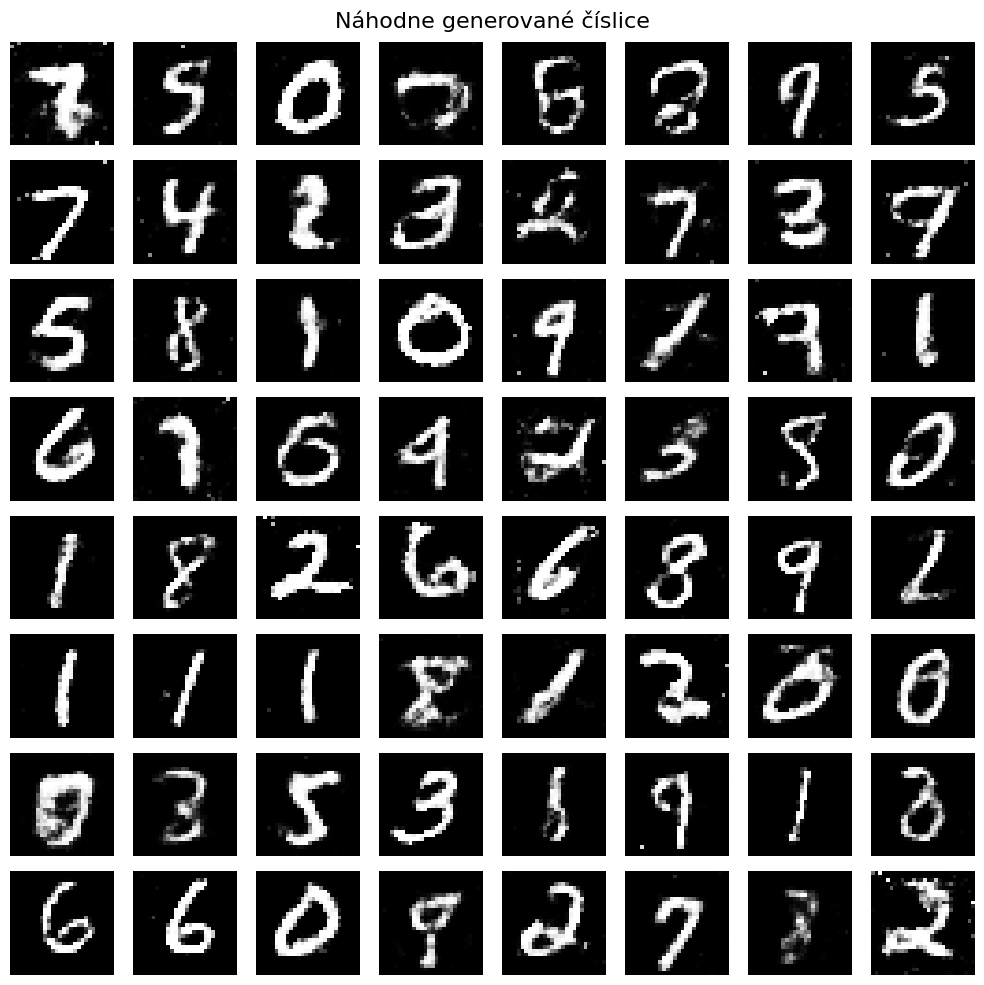

In [8]:
print("="*60)
print("GENERATING NEW DIGIT IMAGES")
print("="*60)

generator.eval()
with torch.no_grad():
    z = torch.randn(64, LATENT_DIM, device=device)
    generated = generator(z)

plt.figure(figsize=(10, 10))
for i in range(64):
    plt.subplot(8, 8, i+1)
    plt.imshow(generated[i].cpu().squeeze(), cmap='gray')
    plt.axis('off')
plt.suptitle('Náhodne generované číslice', fontsize=16)
plt.tight_layout()
plt.show()


## 8. Latent Space Linear Interpolation ($z_1 \to z_2$)


INTERPOLÁCIA V LATENTNOM PRIESTORE


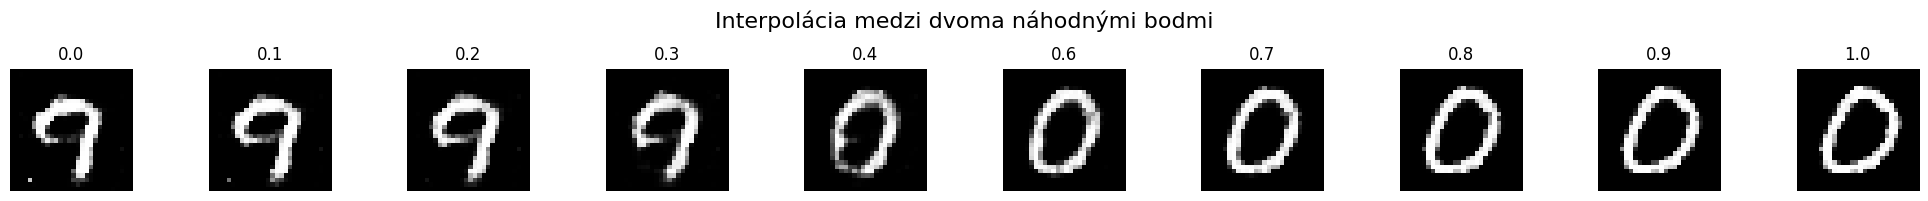

In [9]:
print("="*60)
print("LATENT SPACE INTERPOLATION")
print("="*60)

generator.eval()
with torch.no_grad():
    z1 = torch.randn(1, LATENT_DIM, device=device)
    z2 = torch.randn(1, LATENT_DIM, device=device)

    steps = 10
    interpolated_imgs = []

    for alpha in np.linspace(0, 1, steps):
        z_interp = (1 - alpha) * z1 + alpha * z2 # interpolacia
        img = generator(z_interp)
        interpolated_imgs.append(img.cpu().squeeze())

    plt.figure(figsize=(20, 2))
    for i, img in enumerate(interpolated_imgs):
        plt.subplot(1, steps, i+1)
        plt.imshow(img, cmap='gray')
        plt.title(f'{i/(steps-1):.1f}')
        plt.axis('off')
    plt.suptitle('Interpolácia medzi dvoma náhodnými bodmi', fontsize=16)
    plt.tight_layout()
    plt.show()


## 9. Ground Truth Real vs Generated Fakes Comparison


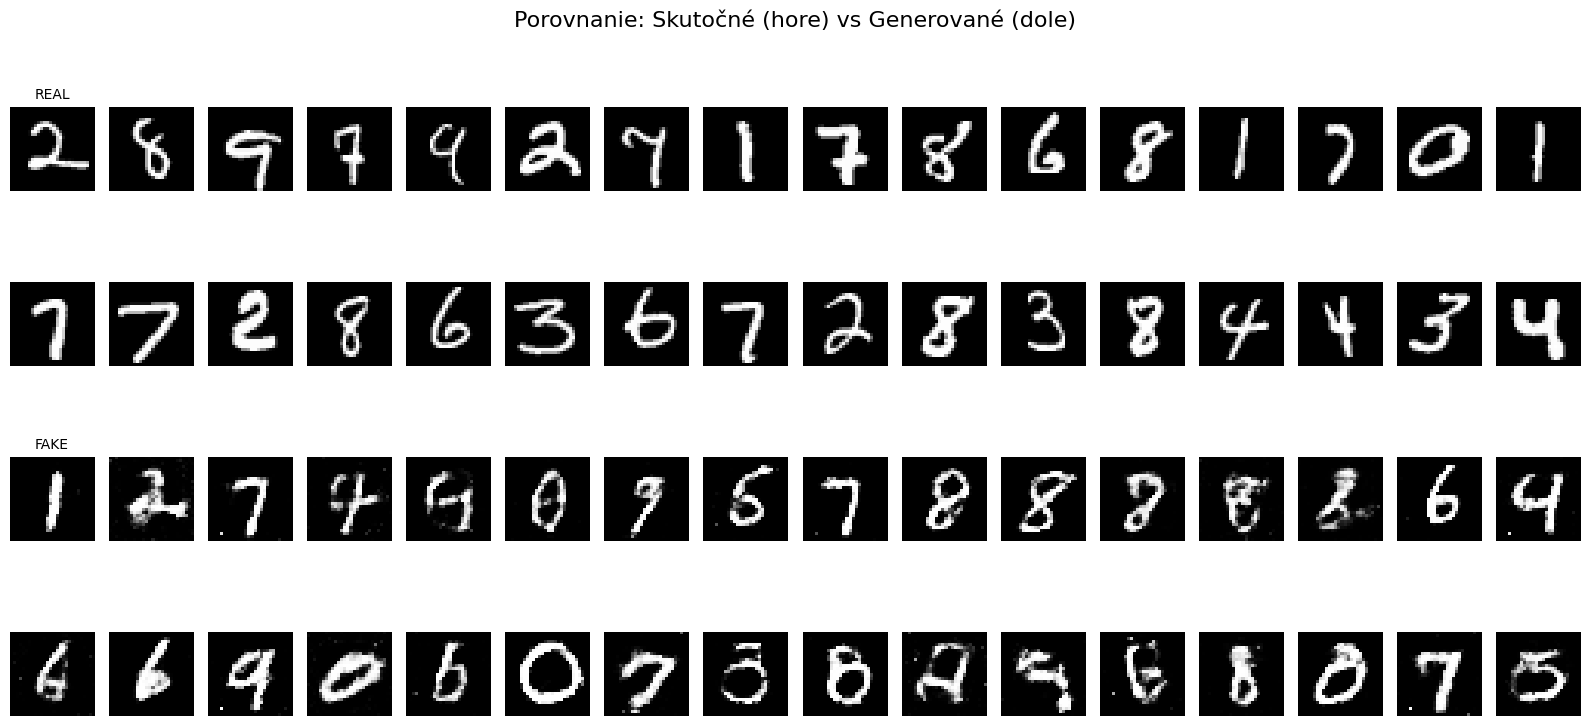

In [10]:
# Load real images
real_imgs, _ = next(iter(train_loader))
real_imgs = real_imgs[:32]

# Vygenerujeme fake obrázky
generator.eval()
with torch.no_grad():
    z = torch.randn(32, LATENT_DIM, device=device)
    fake_imgs = generator(z)

# Vizualizácia
plt.figure(figsize=(16, 8))

# Skutočné
for i in range(32):
    plt.subplot(4, 16, i+1)
    plt.imshow(real_imgs[i].squeeze(), cmap='gray')
    plt.axis('off')
    if i == 0:
        plt.title('REAL', fontsize=10)

# Fake
for i in range(32):
    plt.subplot(4, 16, 32+i+1)
    plt.imshow(fake_imgs[i].cpu().squeeze(), cmap='gray')
    plt.axis('off')
    if i == 0:
        plt.title('FAKE', fontsize=10)

plt.suptitle('Porovnanie: Skutočné (hore) vs Generované (dole)', fontsize=16)
plt.tight_layout()
plt.show()


## 10. Conclusion & Theoretical Insights

**Key Observations on Adversarial Training Dynamics:**
- **Non-Stationary Optimization:** GAN training is inherently non-stationary because the loss surface evolves dynamically with the adversary's parameters.
- **Mode Collapse Vulnerability:** Imbalances in learning rates can lead the generator to produce repetitive digit styles that trick the discriminator rather than spanning the true multi-modal distribution.
- **Nash Equilibrium Target:** The ideal steady-state convergence point occurs when the discriminator accuracy hovers around ~50% (random guess), indicating that generated samples are indistinguishable from real MNIST digits.
- **Latent Manifold Continuity:** Linear spherical interpolation between arbitrary noise vectors produces smooth, continuous morphing between distinct digits, confirming that the generator has learned a meaningful continuous latent representation.
